# Actividad práctica — Módulo 1
## Procesamiento y análisis de datos con Python

### Introducción

El presente trabajo tiene como objetivo aplicar herramientas básicas de Python para el procesamiento y análisis de datos, utilizando un conjunto de datos de ventas minoristas (*Online Retail*).

A lo largo de la actividad se realizará una exploración inicial de los datos, se evaluará su calidad y se aplicarán procedimientos de limpieza cuando sean necesarios. Posteriormente, se llevará a cabo un análisis exploratorio de datos (EDA), mediante estadísticas descriptivas y visualizaciones, para identificar patrones y responder preguntas de investigación.

El desarrollo se realizará en Google Colab, utilizando Python y la biblioteca pandas para manipular y analizar la información.

## Objetivos y preguntas de investigación

**Objetivo del análisis**

Identificar qué productos concentran la mayor proporción de los ingresos estimados del negocio y comprobar si se observa un patrón similar al principio de Pareto, conocido como regla 80/20.

El principio de Pareto plantea que, en determinadas situaciones, una proporción reducida de elementos puede explicar una proporción elevada de un resultado. En este trabajo investigaremos si pocos productos representan aproximadamente el 80 % de los ingresos estimados, sin asumir que esa relación se cumple de antemano.

**Pregunta de investigación 1:** ¿Qué productos concentran la mayor proporción de los ingresos estimados y cuántos se necesitan para alcanzar el 80 % del total?

**Aclaración:** el dataset no contiene información de costos, por lo que calcularemos ingresos estimados a partir de la cantidad y el precio unitario, no ganancias.

**Pregunta de investigación 2:** ¿Qué productos acumulan el 20 % inferior de los ingresos estimados y qué proporción del catálogo representan?

Buscaremos identificar los productos que menos ingresos estimados generan, ordenándolos de menor a mayor y calculando su participación acumulada. Así podremos observar cuántos productos concentran ese tramo inferior de ingresos y qué proporción del catálogo representan.

**Aclaración:** este análisis se refiere a ingresos estimados, no a ganancias ni rentabilidad, ya que el dataset no contiene información de costos.

**Pregunta de investigación 3:** ¿Cuántos clientes con ingresos estimados positivos se necesitan para alcanzar el 80 % de esos ingresos?

Esta pregunta busca identificar cuántos clientes con ingresos estimados positivos concentran el 80 % de esos ingresos dentro de la muestra analizada. Para responderla, sumaremos los ingresos estimados por cliente identificado y ordenaremos los clientes de mayor a menor ingreso, calculando su participación acumulada.

**Aclaración:** el análisis considera únicamente clientes con ingresos netos estimados positivos y con identificador disponible. Por lo tanto, los resultados no representan necesariamente a todos los clientes del negocio.

## **1.** Carga y exploración inicial de los datos

In [1]:
import pandas as pd

In [2]:
from google.colab import files

archivo = files.upload()

Saving Online_Retail_muestra_400_filas.csv to Online_Retail_muestra_400_filas.csv


In [3]:
data_set = pd.read_csv("Online_Retail_muestra_400_filas.csv")

In [4]:
data_set.head()

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
0,536531,22727,DESPERTADOR BAKELIKE ROJO,9,2010-12-01 13:23:00,3.75,15485.0,Reino Unido
1,536531,22726,DESPERTADOR BAKELIKE VERDE,9,2010-12-01 13:23:00,3.75,15485.0,Reino Unido
2,536532,20685,FELPUDO ROJO RETROPUNTO,2,2010-12-01 13:24:00,7.95,12433.0,Noruega
3,536593,22366,FELPUDO AIRMAIL,2,2010-12-01 17:15:00,7.95,16835.0,Reino Unido
4,536623,22815,TARJETA PSYCHEDELIC MANZANAS,24,2010-12-02 10:39:00,0.42,15601.0,Reino Unido


In [5]:
data_set.shape

(400, 8)

In [6]:
data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   NumeroFactura        400 non-null    object 
 1   CodigoProducto       400 non-null    object 
 2   DescripcionProducto  399 non-null    object 
 3   Cantidad             400 non-null    int64  
 4   FechaFactura         400 non-null    object 
 5   PrecioUnitario       400 non-null    float64
 6   IDCliente            303 non-null    float64
 7   Pais                 400 non-null    object 
dtypes: float64(2), int64(1), object(5)
memory usage: 25.1+ KB


## **2.** Diagnóstico y calidad de los datos

### 2.1. Revisar y convertir los tipos de datos

Diagnóstico inicial

Al revisar los tipos de datos del dataset, identificamos que algunas columnas estaban almacenadas como texto (object), otras como números enteros (int64) y otras como números decimales (float64). También observamos que la columna FechaFactura estaba almacenada como texto, aunque contiene fechas.

In [7]:
# Revisamos el tipo de dato de cada columna antes de realizar conversiones.
data_set.dtypes

,0
NumeroFactura,object
CodigoProducto,object
DescripcionProducto,object
Cantidad,int64
FechaFactura,object
PrecioUnitario,float64
IDCliente,float64
Pais,object


In [8]:
# Convertimos FechaFactura al tipo fecha para poder analizar períodos y tendencias.
data_set["FechaFactura"] = pd.to_datetime(data_set["FechaFactura"], errors="coerce")

# Verificamos el tipo de dato después de la conversión.
data_set["FechaFactura"].dtype

dtype('<M8[ns]')

In [9]:
# Contamos cuántas fechas quedaron nulas después de la conversión.
data_set["FechaFactura"].isnull().sum()

np.int64(0)

In [10]:
# Revisamos cuántos valores distintos hay en NumeroFactura.
data_set["NumeroFactura"].nunique()

387

In [11]:
# Contamos cuántos identificadores de cliente distintos hay, sin contar los valores nulos.
data_set["IDCliente"].nunique()

251

In [12]:
# Convertimos IDCliente a un tipo entero que admite valores nulos.
data_set["IDCliente"] = data_set["IDCliente"].astype("Int64")

# Verificamos el tipo de dato después de la conversión.
data_set["IDCliente"].dtype

Int64Dtype()

In [13]:
# Verificamos el tipo de dato de CodigoProducto.
data_set["CodigoProducto"].dtype

dtype('O')

In [14]:
# Verificamos el tipo de dato de PrecioUnitario.
data_set["PrecioUnitario"].dtype

dtype('float64')

In [15]:
# Verificamos el tipo de dato de Cantidad.
data_set["Cantidad"].dtype

dtype('int64')

In [16]:
# Verificamos el tipo de dato de Pais.
data_set["Pais"].dtype

dtype('O')

In [17]:
# Verificamos los tipos de datos de todas las columnas después de las revisiones y conversiones.
data_set.dtypes

,0
NumeroFactura,object
CodigoProducto,object
DescripcionProducto,object
Cantidad,int64
FechaFactura,datetime64[ns]
PrecioUnitario,float64
IDCliente,Int64
Pais,object


**Resultado:** identificamos que `FechaFactura` e `IDCliente` necesitaban conversión. Transformamos `FechaFactura` a formato fecha y `IDCliente` a entero que admite valores nulos. Las demás columnas ya tenían tipos adecuados para la información que contienen. Verificamos que la conversión de fechas no generara nuevos valores nulos.

### 2.2. Identificación y tratamiento de valores nulos

In [18]:
# Contamos cuántos valores nulos hay en cada columna del dataset.
data_set.isnull().sum()

,0
NumeroFactura,0
CodigoProducto,0
DescripcionProducto,1
Cantidad,0
FechaFactura,0
PrecioUnitario,0
IDCliente,97
Pais,0


In [19]:
# Buscamos los registros que no tienen descripción del producto.
data_set[data_set["DescripcionProducto"].isnull()]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
326,574257,72818,NaN,-3,2011-11-03 13:46:00,0.0,<NA>,Reino Unido


In [20]:
# Buscamos registros que no tienen identificador de cliente
# y mostramos solamente los primeros 10 resultados.

data_set[data_set["IDCliente"].isnull()].head(10)

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
5,536876,22251,PÁJAROCASA DECORACIÓN MAGIC JARDÍN,1,2010-12-03 11:36:00,2.51,<NA>,Reino Unido
6,536876,84945,MULTI COLOR PLATEADO PORTAVELAS PARA VELA DE TÉ,6,2010-12-03 11:36:00,1.84,<NA>,Reino Unido
11,537434,20975,12 LÁPICES PEQUEÑO TUBE ROJO RETROPUNTO,7,2010-12-06 16:57:00,1.28,<NA>,Reino Unido
12,537434,22621,TRADITIONAL KNITLATAG NANCY,2,2010-12-06 16:57:00,1.45,<NA>,Reino Unido
14,537645,85039a,SET/4 ROJO MINI ROSA VELA IN CUENCO,1,2010-12-07 15:34:00,3.36,<NA>,Reino Unido
17,538071,22732,3D VINTAGE NAVIDAD STICKERS,1,2010-12-09 14:09:00,2.51,<NA>,Reino Unido
20,538349,90030B,ROJO KUKUI COCONUT SEMILLA COLLAR,1,2010-12-10 14:59:00,5.94,<NA>,Reino Unido
22,538566,22497,JUEGO DE 2 LATAS VINTAGE BAÑO,1,2010-12-13 11:21:00,8.47,<NA>,Reino Unido
28,539492,22616,PAQUETE DE 12 LONDRES TISSUES,1,2010-12-20 10:14:00,0.85,<NA>,Reino Unido
29,539958,85132A,CHARLIE + LOLA GALLETITAS LATAS,3,2010-12-23 13:26:00,8.47,<NA>,Reino Unido


In [21]:
# Mostramos los primeros 10 registros que no tienen IDCliente.
data_set[data_set["IDCliente"].isnull()].head(10)

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
5,536876,22251,PÁJAROCASA DECORACIÓN MAGIC JARDÍN,1,2010-12-03 11:36:00,2.51,<NA>,Reino Unido
6,536876,84945,MULTI COLOR PLATEADO PORTAVELAS PARA VELA DE TÉ,6,2010-12-03 11:36:00,1.84,<NA>,Reino Unido
11,537434,20975,12 LÁPICES PEQUEÑO TUBE ROJO RETROPUNTO,7,2010-12-06 16:57:00,1.28,<NA>,Reino Unido
12,537434,22621,TRADITIONAL KNITLATAG NANCY,2,2010-12-06 16:57:00,1.45,<NA>,Reino Unido
14,537645,85039a,SET/4 ROJO MINI ROSA VELA IN CUENCO,1,2010-12-07 15:34:00,3.36,<NA>,Reino Unido
17,538071,22732,3D VINTAGE NAVIDAD STICKERS,1,2010-12-09 14:09:00,2.51,<NA>,Reino Unido
20,538349,90030B,ROJO KUKUI COCONUT SEMILLA COLLAR,1,2010-12-10 14:59:00,5.94,<NA>,Reino Unido
22,538566,22497,JUEGO DE 2 LATAS VINTAGE BAÑO,1,2010-12-13 11:21:00,8.47,<NA>,Reino Unido
28,539492,22616,PAQUETE DE 12 LONDRES TISSUES,1,2010-12-20 10:14:00,0.85,<NA>,Reino Unido
29,539958,85132A,CHARLIE + LOLA GALLETITAS LATAS,3,2010-12-23 13:26:00,8.47,<NA>,Reino Unido


In [22]:
# Calculamos el porcentaje de registros que no tienen identificador de cliente.
(data_set["IDCliente"].isnull().sum() / len(data_set)) * 100

np.float64(24.25)

In [23]:
# Buscamos todos los registros del producto cuyo código es 72818.
data_set[data_set["CodigoProducto"] == "72818"]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
326,574257,72818,NaN,-3,2011-11-03 13:46:00,0.0,<NA>,Reino Unido


In [24]:
# Identificamos registros con cantidades negativas o precios unitarios iguales a cero.
data_set[(data_set["Cantidad"] < 0) | (data_set["PrecioUnitario"] == 0)]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
56,C541863,21231,SWEETCORAZÓN DE CERÁMICA TRINKET CAJA,-9,2011-01-23 16:08:00,1.06,13798,Reino Unido
71,C543611,21730,DE VIDRIO ESTRELLA FROSTED PORTAVELAS PARA VEL...,-1,2011-02-10 14:38:00,4.95,17850,Reino Unido
92,C545997,22634,CHILDS BREAKFAST JUEGO SPACEBOY,-1,2011-03-08 14:35:00,9.95,12679,Francia
101,C546730,22720,JUEGO DE 3 TORTA LATAS PANTRY DECARTEL,-1,2011-03-16 11:39:00,4.95,18183,Reino Unido
126,C549783,22060,GRANDE TORTA SOPORTE COLGANTE CORAZONES,-5,2011-04-12 11:50:00,3.95,16558,Reino Unido
129,C550355,M,Manual,-1,2011-04-18 10:29:00,222.75,13811,Alemania
204,C559030,84857C,ROSA MONTE CARLO HANDBOLSA,-1,2011-07-05 14:51:00,1.95,16571,Reino Unido
310,C572489,22465,COLGANTE METAL ESTRELLA FAROL,-5,2011-10-24 13:59:00,1.65,17119,Reino Unido
326,574257,72818,NaN,-3,2011-11-03 13:46:00,0.00,<NA>,Reino Unido
347,576673,22548,adjustment,4,2011-11-16 11:59:00,0.00,<NA>,Reino Unido


In [25]:
# Contamos los registros que tienen cantidad negativa o precio unitario igual a cero.
((data_set["Cantidad"] < 0) | (data_set["PrecioUnitario"] == 0)).sum()

np.int64(11)

In [26]:
# Reemplazamos la descripción nula por un texto que indica que falta ese dato.
data_set["DescripcionProducto"] = data_set["DescripcionProducto"].fillna("Descripción no disponible")

Tratamiento de valores nulos en la descripción

Durante la exploración se detectó un registro sin descripción del producto. Al revisar el registro, observamos que el código del producto es 72818, pero no encontramos otra fila en la muestra que nos permita recuperar su descripción.

**Conclusión:** como no podemos determinar la descripción correcta con la información disponible, reemplazaremos el valor nulo por el texto "Descripción no disponible". De esta manera, conservamos el registro y dejamos explícito que el dato original falta, sin inventar información.

In [27]:
# Verificamos cuántos valores nulos quedan en la descripción del producto.
data_set["DescripcionProducto"].isnull().sum()

np.int64(0)

**Verificación:** luego del reemplazo, la columna `DescripcionProducto` no presenta valores nulos. Se conservó el registro y se indicó que la descripción no estaba disponible, sin inventar información.

**Tratamiento de valores nulos en IDCliente**

Se detectaron 97 registros sin identificador de cliente, equivalentes al 24,25 % de las 400 filas del dataset. Al revisar una muestra de estos registros, observamos que conservan información sobre productos, cantidades, fechas, precios y países.

**Conclusión:** conservaremos estos registros y mantendremos los valores de IDCliente como nulos, ya que no contamos con información suficiente para identificar a los clientes. De esta manera, evitamos inventar datos y preservamos la información disponible para otros análisis.

In [28]:
# Contamos los valores nulos que siguen presentes en la columna IDCliente.
data_set["IDCliente"].isnull().sum()

np.int64(97)

In [29]:
# Mostramos los primeros 10 registros sin IDCliente para revisar sus demás datos.
data_set[data_set["IDCliente"].isnull()].head(10)

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
5,536876,22251,PÁJAROCASA DECORACIÓN MAGIC JARDÍN,1,2010-12-03 11:36:00,2.51,<NA>,Reino Unido
6,536876,84945,MULTI COLOR PLATEADO PORTAVELAS PARA VELA DE TÉ,6,2010-12-03 11:36:00,1.84,<NA>,Reino Unido
11,537434,20975,12 LÁPICES PEQUEÑO TUBE ROJO RETROPUNTO,7,2010-12-06 16:57:00,1.28,<NA>,Reino Unido
12,537434,22621,TRADITIONAL KNITLATAG NANCY,2,2010-12-06 16:57:00,1.45,<NA>,Reino Unido
14,537645,85039a,SET/4 ROJO MINI ROSA VELA IN CUENCO,1,2010-12-07 15:34:00,3.36,<NA>,Reino Unido
17,538071,22732,3D VINTAGE NAVIDAD STICKERS,1,2010-12-09 14:09:00,2.51,<NA>,Reino Unido
20,538349,90030B,ROJO KUKUI COCONUT SEMILLA COLLAR,1,2010-12-10 14:59:00,5.94,<NA>,Reino Unido
22,538566,22497,JUEGO DE 2 LATAS VINTAGE BAÑO,1,2010-12-13 11:21:00,8.47,<NA>,Reino Unido
28,539492,22616,PAQUETE DE 12 LONDRES TISSUES,1,2010-12-20 10:14:00,0.85,<NA>,Reino Unido
29,539958,85132A,CHARLIE + LOLA GALLETITAS LATAS,3,2010-12-23 13:26:00,8.47,<NA>,Reino Unido


In [30]:
# Contamos los registros sin IDCliente según el país.
data_set[data_set["IDCliente"].isnull()]["Pais"].value_counts()

,count
Pais,
Reino Unido,96
Sin especificar,1


**Observación:** al analizar los registros sin identificador de cliente, encontramos que 96 corresponden al Reino Unido. El registro restante figura como "Sin especificar" en la columna País.

**Conclusión:** debemos verificar el origen de ese valor antes de interpretar la distribución por país. Conservaremos los valores nulos de IDCliente porque no contamos con información para recuperar los identificadores originales.

In [31]:
# Contamos cuántos de los registros sin IDCliente tienen el país vacío.
data_set.loc[data_set["IDCliente"].isnull(), "Pais"].isnull().sum()

np.int64(0)

In [32]:
# Calculamos cuántos registros sin IDCliente tienen descripción de producto disponible.
data_set.loc[data_set["IDCliente"].isnull(), "DescripcionProducto"].notnull().sum()

np.int64(97)

In [33]:
# Contamos los registros sin IDCliente que tienen la cantidad informada.
data_set.loc[data_set["IDCliente"].isnull(), "Cantidad"].notnull().sum()

np.int64(97)

In [34]:
# Contamos los registros sin IDCliente que tienen el precio unitario informado.
data_set.loc[data_set["IDCliente"].isnull(), "PrecioUnitario"].notnull().sum()

np.int64(97)

In [35]:
# Contamos los registros sin IDCliente que tienen la fecha de factura informada.
data_set.loc[data_set["IDCliente"].isnull(), "FechaFactura"].notnull().sum()

np.int64(97)

In [36]:
# Contamos los registros sin IDCliente que tienen el país informado.
data_set.loc[data_set["IDCliente"].isnull(), "Pais"].notnull().sum()

np.int64(97)

In [37]:
# Verificamos cuántos valores nulos quedan en cada columna después del tratamiento.
data_set.isnull().sum()

,0
NumeroFactura,0
CodigoProducto,0
DescripcionProducto,0
Cantidad,0
FechaFactura,0
PrecioUnitario,0
IDCliente,97
Pais,0


**Evaluación y decisión:** los 97 registros sin identificador de cliente tienen informadas las columnas DescripcionProducto, Cantidad, PrecioUnitario, FechaFactura y Pais. Por lo tanto, conservan información útil para analizar productos y ventas. Como no contamos con datos que permitan recuperar los identificadores originales, decidimos conservar los registros y mantener los valores nulos de IDCliente.

### 2.3. Identificación de registros duplicados

In [38]:
# Contamos cuántas filas duplicadas hay en el dataset.
data_set.duplicated().sum()

np.int64(0)

**Resultado y decisión:** no se encontraron filas completamente duplicadas en el dataset. Por lo tanto, no es necesario eliminar registros por duplicación exacta.

### 2.4. Identificación de valores atípicos e inconsistencias

In [39]:
# Identificamos registros con cantidades negativas o precios unitarios iguales a cero.
data_set[(data_set["Cantidad"] < 0) | (data_set["PrecioUnitario"] == 0)]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
56,C541863,21231,SWEETCORAZÓN DE CERÁMICA TRINKET CAJA,-9,2011-01-23 16:08:00,1.06,13798,Reino Unido
71,C543611,21730,DE VIDRIO ESTRELLA FROSTED PORTAVELAS PARA VEL...,-1,2011-02-10 14:38:00,4.95,17850,Reino Unido
92,C545997,22634,CHILDS BREAKFAST JUEGO SPACEBOY,-1,2011-03-08 14:35:00,9.95,12679,Francia
101,C546730,22720,JUEGO DE 3 TORTA LATAS PANTRY DECARTEL,-1,2011-03-16 11:39:00,4.95,18183,Reino Unido
126,C549783,22060,GRANDE TORTA SOPORTE COLGANTE CORAZONES,-5,2011-04-12 11:50:00,3.95,16558,Reino Unido
129,C550355,M,Manual,-1,2011-04-18 10:29:00,222.75,13811,Alemania
204,C559030,84857C,ROSA MONTE CARLO HANDBOLSA,-1,2011-07-05 14:51:00,1.95,16571,Reino Unido
310,C572489,22465,COLGANTE METAL ESTRELLA FAROL,-5,2011-10-24 13:59:00,1.65,17119,Reino Unido
326,574257,72818,Descripción no disponible,-3,2011-11-03 13:46:00,0.00,<NA>,Reino Unido
347,576673,22548,adjustment,4,2011-11-16 11:59:00,0.00,<NA>,Reino Unido


In [40]:
# Contamos los registros con cantidad negativa.
(data_set["Cantidad"] < 0).sum()

np.int64(10)

In [41]:
# Contamos los registros con precio unitario igual a cero.
(data_set["PrecioUnitario"] == 0).sum()

np.int64(2)

In [42]:
# Mostramos los registros cuyo precio unitario es cero.
data_set[data_set["PrecioUnitario"] == 0]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
326,574257,72818,Descripción no disponible,-3,2011-11-03 13:46:00,0.0,<NA>,Reino Unido
347,576673,22548,adjustment,4,2011-11-16 11:59:00,0.0,<NA>,Reino Unido


In [43]:
# Mostramos las facturas de los registros con cantidades negativas.
data_set.loc[data_set["Cantidad"] < 0, ["NumeroFactura", "Cantidad", "PrecioUnitario", "DescripcionProducto"]]

,NumeroFactura,Cantidad,PrecioUnitario,DescripcionProducto
56,C541863,-9,1.06,SWEETCORAZÓN DE CERÁMICA TRINKET CAJA
71,C543611,-1,4.95,DE VIDRIO ESTRELLA FROSTED PORTAVELAS PARA VEL...
92,C545997,-1,9.95,CHILDS BREAKFAST JUEGO SPACEBOY
101,C546730,-1,4.95,JUEGO DE 3 TORTA LATAS PANTRY DECARTEL
126,C549783,-5,3.95,GRANDE TORTA SOPORTE COLGANTE CORAZONES
129,C550355,-1,222.75,Manual
204,C559030,-1,1.95,ROSA MONTE CARLO HANDBOLSA
310,C572489,-5,1.65,COLGANTE METAL ESTRELLA FAROL
326,574257,-3,0.00,Descripción no disponible
363,C578144,-3,2.95,VERDE REGENCY TÉTAZA AND SAUCER


In [44]:
# Contamos las facturas cuyo número comienza con la letra C.
data_set["NumeroFactura"].astype(str).str.startswith("C").sum()

np.int64(9)

In [45]:
# Contamos los registros que tienen factura iniciada en C y cantidad negativa.
(
    data_set["NumeroFactura"].astype(str).str.startswith("C")
    & (data_set["Cantidad"] < 0)
).sum()

np.int64(9)

**Resultado y decisión:** se identificaron 10 registros con cantidades negativas; 9 corresponden a facturas cuyo número comienza con `C`. Estos registros podrían representar devoluciones o cancelaciones, por lo que se conservarán para no eliminar información potencialmente relevante.

**Análisis de precios unitarios iguales a cero:** se identificaron 2 registros con precio unitario igual a cero. Uno corresponde a un producto sin descripción disponible y el otro a un registro identificado como *adjustment*. Como no contamos con información suficiente para determinar si estos valores son errores, se conservarán sin modificaciones.

In [46]:
# Contamos cuántos valores distintos tiene cada columna.
data_set.nunique()

,0
NumeroFactura,387
CodigoProducto,350
DescripcionProducto,350
Cantidad,34
FechaFactura,386
PrecioUnitario,82
IDCliente,251
Pais,16


**Resultado y decisión:** todas las columnas presentan más de un valor distinto. No se identificaron columnas sin variación que deban eliminarse por este motivo.

In [47]:
# Obtenemos la cantidad mínima y máxima registrada.
data_set["Cantidad"].agg(["min", "max"])

,Cantidad
min,-9
max,600


In [48]:
# Mostramos el registro que tiene la cantidad máxima.
data_set.loc[data_set["Cantidad"] == data_set["Cantidad"].max()]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
114,548336,15036,SURTIDO COLORS SILK FAN,600,2011-03-30 14:06:00,0.65,13082,Reino Unido


In [49]:
# Mostramos el registro con la cantidad mínima.
data_set.loc[data_set["Cantidad"] == data_set["Cantidad"].min()]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
56,C541863,21231,SWEETCORAZÓN DE CERÁMICA TRINKET CAJA,-9,2011-01-23 16:08:00,1.06,13798,Reino Unido


**Revisión de cantidades:** los valores oscilan entre -9 y 600 unidades. El máximo corresponde a una compra de un producto por 600 unidades, que no necesariamente es un error. El mínimo es -9 y podría representar una devolución o cancelación. Se conservan ambos registros por no contar con evidencia suficiente para modificarlos.

In [50]:
# Obtenemos el precio unitario mínimo y máximo registrado.
data_set["PrecioUnitario"].agg(["min", "max"])

,PrecioUnitario
min,0.00
max,222.75


In [51]:
# Mostramos el registro que tiene el precio unitario máximo.
data_set.loc[data_set["PrecioUnitario"] == data_set["PrecioUnitario"].max()]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
129,C550355,M,Manual,-1,2011-04-18 10:29:00,222.75,13811,Alemania


**Revisión de precios:** los precios unitarios oscilan entre 0 y 222,75. Se identificaron dos registros con precio cero y un precio máximo asociado a un artículo denominado *Manual*, con cantidad negativa. Sin evidencia suficiente de error, se conservan los valores originales.

In [52]:
# Buscamos registros con precio unitario negativo.
data_set[data_set["PrecioUnitario"] < 0]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais


**Resultado y decisión:** no se encontraron precios unitarios negativos en la muestra. Por lo tanto, no es necesario realizar correcciones en esta variable por este motivo.

In [53]:
# Contamos los registros con cantidad igual a cero.
(data_set["Cantidad"] == 0).sum()

np.int64(0)

**Resultado y decisión:** no se encontraron registros con cantidad igual a cero. No se requieren correcciones en la variable `Cantidad` por este motivo.

In [54]:
# Resumimos las principales estadísticas de las variables numéricas.
data_set[["Cantidad", "PrecioUnitario"]].describe()

,Cantidad,PrecioUnitario
count,400.000000,400.000000
mean,9.617500,4.061800
std,35.063154,12.041687
min,-9.000000,0.000000
25%,1.000000,1.250000
50%,4.000000,2.080000
75%,10.000000,4.130000
max,600.000000,222.750000


**Análisis descriptivo:** la cantidad promedio es de 9,62 unidades y el precio unitario promedio es de 4,06. Los máximos de 600 unidades y 222,75 presentan valores superiores al resto y fueron revisados individualmente. Sin evidencia suficiente de error, se conservan los registros originales.

In [55]:
# Mostramos los países y la cantidad de registros de cada uno.
data_set["Pais"].value_counts(dropna=False)

,count
Pais,
Reino Unido,357
Francia,10
Alemania,9
España,5
Irlanda,5
Noruega,2
Australia,2
Italia,2
Austria,1


In [56]:
# Mostramos el registro cuyo país figura como "Sin especificar".
data_set.loc[data_set["Pais"] == "Sin especificar"]

,NumeroFactura,CodigoProducto,DescripcionProducto,Cantidad,FechaFactura,PrecioUnitario,IDCliente,Pais
368,578539,22559,SEASIDE FLYING DISC,12,2011-11-24 14:55:00,1.25,<NA>,Sin especificar


**Resultado y decisión:** se identificó un registro cuyo país figura como `"Sin especificar"`. Como no contamos con información para determinar el país correcto, conservamos el valor original sin modificarlo.

In [57]:
# Mostramos las descripciones de productos más frecuentes.
data_set["DescripcionProducto"].value_counts().head(10)

,count
DescripcionProducto,
ROSAS REGENCY TÉTAZA AND SAUCER,4
MULTI COLOR PLATEADO PORTAVELAS PARA VELA DE TÉ,3
6 CINTAS RUSTIC CHARM,3
CAJA OF VINTAGE BLOQUES CON LETRAS,3
DE MADERA ESTRELLA NAVIDAD SCANDINAVIAN,3
VERDE REGENCY TÉTAZA AND SAUCER,3
RECYCLED ACAPULCO MAT ROJO,2
ROSA FELIZ CUMPLEAÑOS BANDERINES,2
MARFIL COLGANTE DECORACIÓN CORAZÓN,2


In [58]:
# Contamos las descripciones vacías o que contienen solamente espacios.
data_set["DescripcionProducto"].str.strip().eq("").sum()

np.int64(0)

**Resultado y decisión:** no se encontraron descripciones vacías ni compuestas únicamente por espacios. No se requieren correcciones adicionales en `DescripcionProducto` por este motivo.

In [59]:
# Verificamos la cantidad de filas y columnas del dataset después de las revisiones.
data_set.shape

(400, 8)

**Resultado del diagnóstico:** se conservaron las 400 filas y las 8 columnas originales. Se revisaron los tipos de datos, los valores nulos, los duplicados exactos y posibles inconsistencias. Los registros sospechosos se conservaron cuando no hubo evidencia suficiente para considerarlos errores.

## **3.** Preparación y limpieza de los datos

In [60]:
# Creamos una copia del dataset revisado para trabajar con los datos limpios.
data_set_limpio = data_set.copy()

# Verificamos la cantidad de filas y columnas del dataset limpio.
data_set_limpio.shape

(400, 8)

In [61]:
# Verificamos los tipos de datos del dataset limpio.
data_set_limpio.dtypes

,0
NumeroFactura,object
CodigoProducto,object
DescripcionProducto,object
Cantidad,int64
FechaFactura,datetime64[ns]
PrecioUnitario,float64
IDCliente,Int64
Pais,object


In [62]:
# Verificamos los valores nulos del dataset limpio.
data_set_limpio.isnull().sum()

,0
NumeroFactura,0
CodigoProducto,0
DescripcionProducto,0
Cantidad,0
FechaFactura,0
PrecioUnitario,0
IDCliente,97
Pais,0


**Resultado final:** se creó `data_set_limpio` con 400 filas y 8 columnas. Se conservaron los tipos de datos revisados y los registros originales, manteniendo los 97 valores nulos de `IDCliente` por no contar con información para recuperarlos.

## **4.** Análisis exploratorio de datos (EDA)

In [63]:
# Calculamos estadísticas descriptivas de las variables numéricas.
data_set_limpio.describe()

,Cantidad,FechaFactura,PrecioUnitario,IDCliente
count,400.000000,400,400.000000,303.0
mean,9.617500,2011-06-25 17:17:41.550000128,4.061800,15234.726073
min,-9.000000,2010-12-01 13:23:00,0.000000,12353.0
25%,1.000000,2011-03-15 06:57:30,1.250000,13739.0
50%,4.000000,2011-07-03 12:39:30,2.080000,15128.0
75%,10.000000,2011-10-13 13:19:30,4.130000,16719.0
max,600.000000,2011-12-07 10:35:00,222.750000,18283.0
std,35.063154,NaN,12.041687,1778.182862


In [64]:
# Contamos los registros de cada país en el dataset limpio.
data_set_limpio["Pais"].value_counts()

,count
Pais,
Reino Unido,357
Francia,10
Alemania,9
España,5
Irlanda,5
Noruega,2
Australia,2
Italia,2
Austria,1


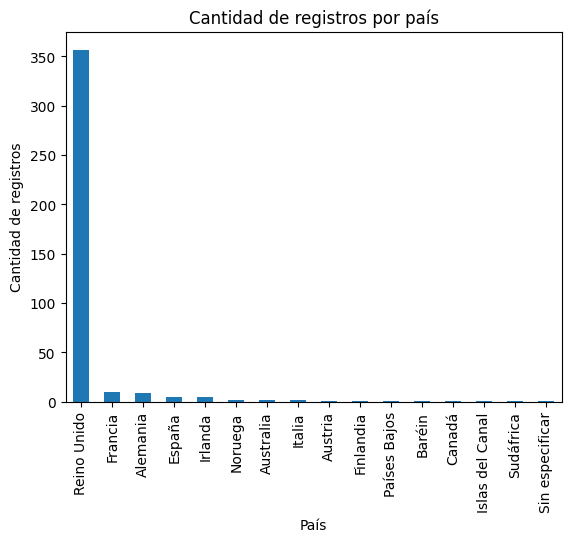

In [65]:
# Graficamos la cantidad de registros por país.
data_set_limpio["Pais"].value_counts().plot(
    kind="bar",
    title="Cantidad de registros por país",
    xlabel="País",
    ylabel="Cantidad de registros"
);

**Interpretación:** el Reino Unido concentra 357 de los 400 registros de la muestra. Francia y Alemania aparecen a continuación, con 10 y 9 registros, respectivamente. Esta distribución desigual debe tenerse en cuenta al comparar países.

In [66]:
# Mostramos la distribución de las cantidades mediante estadísticas descriptivas.
data_set_limpio["Cantidad"].describe()

,Cantidad
count,400.000000
mean,9.617500
std,35.063154
min,-9.000000
25%,1.000000
50%,4.000000
75%,10.000000
max,600.000000


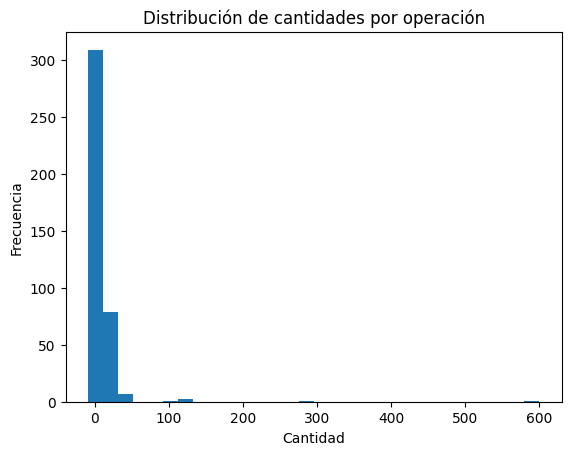

In [67]:
# Graficamos la distribución de las cantidades.
data_set_limpio["Cantidad"].plot(
    kind="hist",
    bins=30,
    title="Distribución de cantidades por operación",
    xlabel="Cantidad",
    ylabel="Frecuencia"
);

In [68]:
# Calculamos estadísticas descriptivas de los precios unitarios.
data_set_limpio["PrecioUnitario"].describe()

,PrecioUnitario
count,400.000000
mean,4.061800
std,12.041687
min,0.000000
25%,1.250000
50%,2.080000
75%,4.130000
max,222.750000


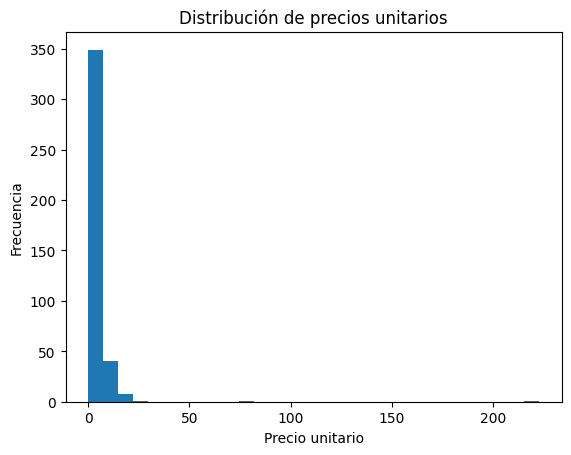

In [69]:
# Graficamos la distribución de los precios unitarios.
data_set_limpio["PrecioUnitario"].plot(
    kind="hist",
    bins=30,
    title="Distribución de precios unitarios",
    xlabel="Precio unitario",
    ylabel="Frecuencia"
);

**Interpretación:** la mayoría de los precios unitarios se concentra en valores bajos. La distribución presenta una cola hacia la derecha debido a algunos precios elevados, entre ellos el máximo de 222,75. Estos valores aumentan el promedio respecto de la mediana.

In [70]:
# Importamos la librería para personalizar los gráficos.
import matplotlib.pyplot as plt

**Interpretación:** el boxplot muestra varios valores atípicos superiores en `Cantidad`, incluido el máximo de 600 unidades. La mayoría de las operaciones se concentra en cantidades pequeñas. Estos valores extremos se conservan porque no hay evidencia suficiente para considerarlos errores.

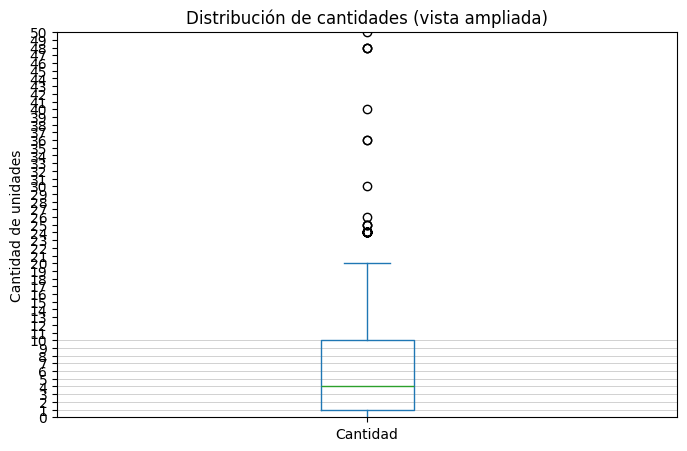

In [71]:
# Creamos el boxplot con escala hasta 50 unidades.
fig, ax = plt.subplots(figsize=(8, 5))
data_set_limpio["Cantidad"].plot(kind="box", ax=ax)

ax.set_ylim(0, 50)
ax.set_yticks(range(0, 51, 1))
ax.set_title("Distribución de cantidades (vista ampliada)")
ax.set_ylabel("Cantidad de unidades")

# Desactivamos todas las líneas de cuadrícula.
ax.grid(False)

# Dibujamos líneas horizontales solo entre 0 y 10.
for y in range(0, 11):
    ax.axhline(y, color="gray", linewidth=0.5, alpha=0.5, zorder=0)

plt.show()

**Interpretación:** el 50 % central de las operaciones registra cantidades entre 1 y 10 unidades. La mediana es de 4 unidades, por lo que la mitad de los registros presenta cantidades de hasta 4 unidades. El rango intercuartílico es de 9 unidades. También se observan valores atípicos superiores, que se conservan porque no hay evidencia suficiente para considerarlos errores.

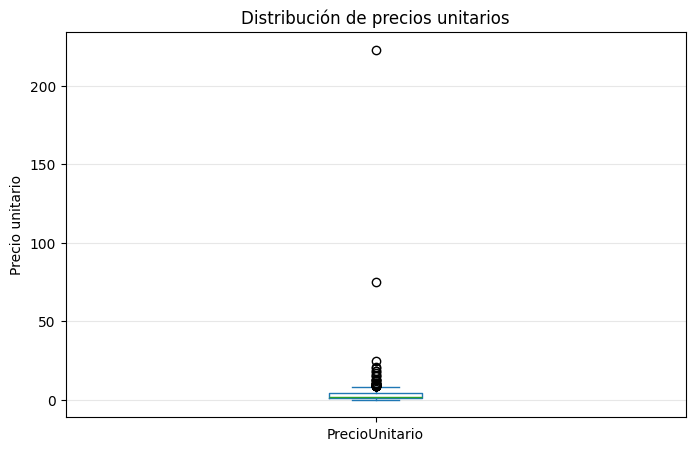

In [72]:
# Creamos el boxplot de precios unitarios.
fig, ax = plt.subplots(figsize=(8, 5))
data_set_limpio["PrecioUnitario"].plot(kind="box", ax=ax)

ax.set_title("Distribución de precios unitarios")
ax.set_ylabel("Precio unitario")
ax.grid(axis="y", alpha=0.3)

plt.show()

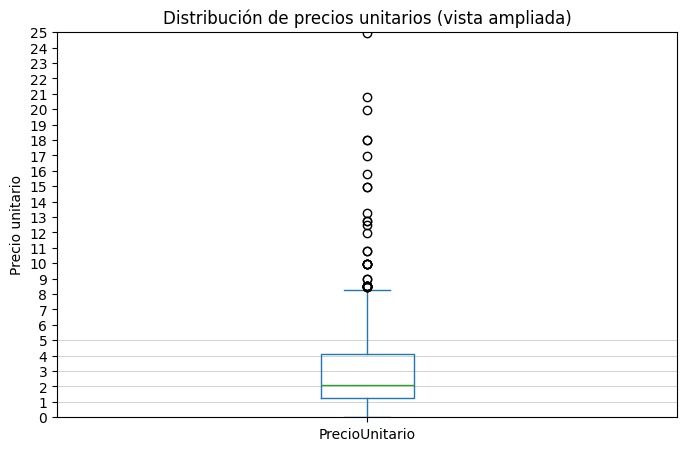

In [73]:
# Ampliamos la vista para observar mejor los precios habituales.
fig, ax = plt.subplots(figsize=(8, 5))
data_set_limpio["PrecioUnitario"].plot(kind="box", ax=ax)

ax.set_ylim(0, 25)
ax.set_yticks(range(0, 26, 1))
ax.set_title("Distribución de precios unitarios (vista ampliada)")
ax.set_ylabel("Precio unitario")
ax.grid(False)

# Dibujamos líneas horizontales solo entre 0 y 5.
for y in range(0, 6):
    ax.axhline(y, color="gray", linewidth=0.5, alpha=0.5, zorder=0)

plt.show()

**Interpretación:** el 50 % central de los precios unitarios se encuentra entre 1,25 y 4,13, con una mediana de 2,08. Se observan varios valores atípicos superiores, lo que indica una distribución concentrada en precios bajos y algunos precios elevados. Los valores se conservan porque no hay evidencia suficiente para considerarlos errores.

## **5.** Respuesta a las preguntas de investigación

### 5.1. Pregunta 1: ¿Qué productos concentran la mayor proporción de los ingresos estimados y cuántos se necesitan para alcanzar el 80 % del total?

In [74]:
# Calculamos los ingresos estimados de cada registro.
data_set_limpio["IngresosEstimados"] = (
    data_set_limpio["Cantidad"] * data_set_limpio["PrecioUnitario"]
)

# Sumamos los ingresos estimados por producto.
ingresos_por_producto = (
    data_set_limpio
    .groupby(["CodigoProducto", "DescripcionProducto"])["IngresosEstimados"]
    .sum()
    .reset_index()
    .sort_values("IngresosEstimados", ascending=False)
)

# Mostramos los 10 productos con mayores ingresos estimados.
ingresos_por_producto.head(10)

,CodigoProducto,DescripcionProducto,IngresosEstimados
298,82551,LAUNDRY 15C METAL CARTEL,489.60
0,15036,SURTIDO COLORS SILK FAN,390.00
164,22659,LUNCH CAJA I AMOR LONDRES,215.33
318,84879,SURTIDO COLOR PÁJARO ADORNO,108.16
32,21217,ROJO RETROPUNTO ROUND TORTA LATAS,107.40
220,23084,CONEJO NIGHT LUZ,106.72
91,22112,CHOCOLATE BOLSA DE AGUA CALIENTE,102.00
172,22699,ROSAS REGENCY TÉTAZA AND SAUCER,93.63
241,23242,TREASURE LATA BUFFALO BILL,88.80
153,22622,CAJA OF VINTAGE BLOQUES CON LETRAS,88.66


In [75]:
# Calculamos el total de ingresos estimados de todos los productos.
total_ingresos = ingresos_por_producto["IngresosEstimados"].sum()

# Calculamos el porcentaje que representa cada producto.
ingresos_por_producto["PorcentajeIngresos"] = (
    ingresos_por_producto["IngresosEstimados"] / total_ingresos * 100
)

# Calculamos el porcentaje acumulado, de mayor a menor ingreso.
ingresos_por_producto["PorcentajeAcumulado"] = (
    ingresos_por_producto["PorcentajeIngresos"].cumsum()
)

# Mostramos los primeros 15 productos con sus porcentajes.
ingresos_por_producto.head(15).round(2)

,CodigoProducto,DescripcionProducto,IngresosEstimados,PorcentajeIngresos,PorcentajeAcumulado
298,82551,LAUNDRY 15C METAL CARTEL,489.60,7.62,7.62
0,15036,SURTIDO COLORS SILK FAN,390.00,6.07,13.69
164,22659,LUNCH CAJA I AMOR LONDRES,215.33,3.35,17.04
318,84879,SURTIDO COLOR PÁJARO ADORNO,108.16,1.68,18.73
32,21217,ROJO RETROPUNTO ROUND TORTA LATAS,107.40,1.67,20.40
220,23084,CONEJO NIGHT LUZ,106.72,1.66,22.06
91,22112,CHOCOLATE BOLSA DE AGUA CALIENTE,102.00,1.59,23.65
172,22699,ROSAS REGENCY TÉTAZA AND SAUCER,93.63,1.46,25.10
241,23242,TREASURE LATA BUFFALO BILL,88.80,1.38,26.49
153,22622,CAJA OF VINTAGE BLOQUES CON LETRAS,88.66,1.38,27.87


In [76]:
# Identificamos cuántos productos se necesitan para alcanzar el 80 %.
productos_hasta_80 = ingresos_por_producto[
    ingresos_por_producto["PorcentajeAcumulado"] <= 80
]

# Incluimos el primer producto que hace que el acumulado alcance o supere el 80 %.
if len(productos_hasta_80) < len(ingresos_por_producto):
    productos_hasta_80 = ingresos_por_producto.iloc[:len(productos_hasta_80) + 1]

# Mostramos el resultado.
productos_hasta_80.tail(1)[
    ["CodigoProducto", "DescripcionProducto", "PorcentajeAcumulado"]
]

,CodigoProducto,DescripcionProducto,PorcentajeAcumulado
73,21933,ROSA VINTAGE PAISLEY PICNIC BOLSA,80.127972


In [77]:
# Contamos los productos necesarios para alcanzar el 80 %.
cantidad_productos_80 = len(productos_hasta_80)

# Calculamos qué porcentaje del catálogo representan.
porcentaje_catalogo_80 = (
    cantidad_productos_80 / len(ingresos_por_producto) * 100
)

print(f"Productos necesarios para alcanzar el 80 %: {cantidad_productos_80}")
print(f"Total de productos analizados: {len(ingresos_por_producto)}")
print(f"Porcentaje del catálogo: {porcentaje_catalogo_80:.2f}%")

Productos necesarios para alcanzar el 80 %: 121
Total de productos analizados: 350
Porcentaje del catálogo: 34.57%


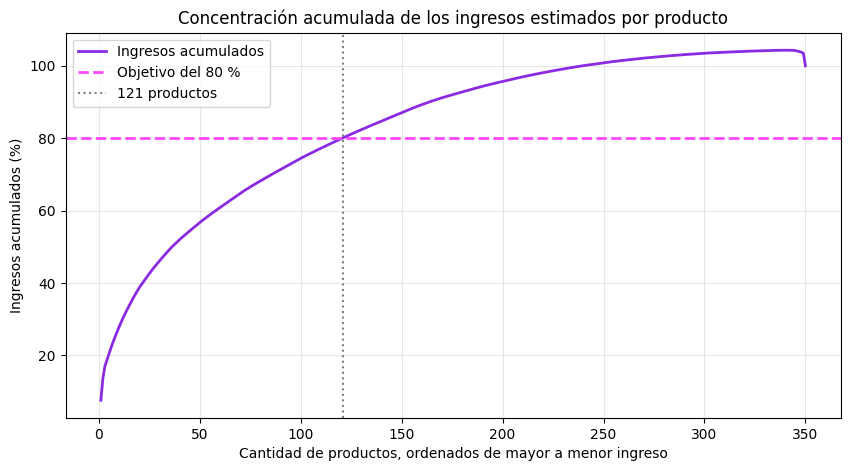

In [78]:
import matplotlib.pyplot as plt

# Graficamos la participación acumulada de los productos.
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(ingresos_por_producto) + 1),
    ingresos_por_producto["PorcentajeAcumulado"],
    color="#8A2BE2",
    linewidth=2,
    label="Ingresos acumulados"
)

# Marcamos el objetivo del 80 % en rosa.
plt.axhline(
    y=80,
    color="#FF47FF",
    linestyle="--",
    linewidth=2,
    label="Objetivo del 80 %"
)

# Marcamos la cantidad de productos necesaria para alcanzar el 80 %.
plt.axvline(
    x=cantidad_productos_80,
    color="#808080",
    linestyle=":",
    linewidth=1.5,
    label=f"{cantidad_productos_80} productos"
)

plt.title("Concentración acumulada de los ingresos estimados por producto")
plt.xlabel("Cantidad de productos, ordenados de mayor a menor ingreso")
plt.ylabel("Ingresos acumulados (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Conclusión de la pregunta 1**

En la muestra analizada, se necesitaron 121 de los 350 productos (34,57 % del catálogo) para alcanzar el 80,13 % de los ingresos estimados. Esto muestra que los ingresos se concentran en una parte del catálogo, aunque no se observa una relación exacta 80/20. Estos resultados corresponden a la muestra de 400 registros analizada y no necesariamente representan el comportamiento del negocio completo.

### 5.2. Pregunta 2: ¿Qué productos acumulan el 20 % inferior de los ingresos estimados y qué proporción del catálogo representan?

In [79]:
# Separamos los productos con ingresos estimados positivos.
productos_positivos = ingresos_por_producto[
    ingresos_por_producto["IngresosEstimados"] > 0
].copy()

# Ordenamos de menor a mayor ingreso estimado.
productos_positivos = productos_positivos.sort_values(
    "IngresosEstimados",
    ascending=True
).reset_index(drop=True)

# Calculamos el total de ingresos positivos.
total_ingresos_positivos = productos_positivos["IngresosEstimados"].sum()

# Calculamos la participación y el acumulado sobre los ingresos positivos.
productos_positivos["PorcentajeIngresosPositivos"] = (
    productos_positivos["IngresosEstimados"]
    / total_ingresos_positivos * 100
)

productos_positivos["PorcentajeAcumuladoInferior"] = (
    productos_positivos["PorcentajeIngresosPositivos"].cumsum()
)

# Mostramos los primeros 15 productos.
productos_positivos.head(15).round(2)

,CodigoProducto,DescripcionProducto,IngresosEstimados,PorcentajeIngresos,PorcentajeAcumulado,PorcentajeIngresosPositivos,PorcentajeAcumuladoInferior
0,21394,ROJO POLKADOT BEAKER,0.39,0.01,104.31,0.01,0.01
1,21810,NAVIDAD COLGANTE ESTRELLA WITH CAMPANA,0.39,0.01,104.31,0.01,0.01
2,84731,3 PÁJAROS CANVAS SCREEN,0.39,0.01,104.30,0.01,0.02
3,21899,GARAGE KEY FOB,0.65,0.01,104.30,0.01,0.03
4,21944,KITTENS DECARTEL FLANNEL,0.83,0.01,104.27,0.01,0.04
5,90214C,"LETTER ""C"" BLING LLAVERO",0.83,0.01,104.29,0.01,0.05
6,84536A,ENGLISH ROSA CUADERNO A7 SIZE,0.84,0.01,104.26,0.01,0.06
7,22586,FIELTROCRAFT CABELLOBAND ROSA AND AZUL,0.85,0.01,104.23,0.01,0.08
8,90214W,"LETTER ""W"" BLING LLAVERO",0.85,0.01,104.25,0.01,0.09
9,21889,DE MADERA CAJA OF DOMINOES,1.25,0.02,104.14,0.02,0.11


In [80]:
# Identificamos los productos que acumulan hasta el 20 % de los ingresos positivos.
productos_hasta_20 = productos_positivos[
    productos_positivos["PorcentajeAcumuladoInferior"] <= 20
].copy()

# Incluimos el primer producto que alcanza o supera el 20 %.
if len(productos_hasta_20) < len(productos_positivos):
    productos_hasta_20 = productos_positivos.iloc[
        :len(productos_hasta_20) + 1
    ].copy()

# Mostramos el último producto incluido en ese grupo.
productos_hasta_20.tail(1)[
    ["CodigoProducto", "DescripcionProducto",
     "PorcentajeAcumuladoInferior"]
].round(2)

,CodigoProducto,DescripcionProducto,PorcentajeAcumuladoInferior
205,85150,LADIES & GENTLEMEN METAL CARTEL,20.13


In [81]:
# Contamos los productos que componen el 20 % inferior de los ingresos positivos.
cantidad_productos_20 = len(productos_hasta_20)

# Calculamos qué porcentaje representan sobre los productos con ingresos positivos.
total_productos_positivos = len(productos_positivos)
porcentaje_catalogo_20 = (
    cantidad_productos_20 / total_productos_positivos * 100
)

print(f"Productos del tramo inferior: {cantidad_productos_20}")
print(f"Productos con ingresos positivos analizados: {total_productos_positivos}")
print(f"Porcentaje de productos con ingresos positivos: {porcentaje_catalogo_20:.2f}%")


Productos del tramo inferior: 206
Productos con ingresos positivos analizados: 340
Porcentaje de productos con ingresos positivos: 60.59%


**Conclusión de la pregunta 2**

Al ordenar de menor a mayor los productos con ingresos estimados positivos, se necesitaron **206 de los 340 productos (60,59 %)** para alcanzar el **20,13 % de los ingresos positivos**. Esto muestra que una parte amplia del catálogo aporta una proporción relativamente baja de los ingresos positivos de la muestra. El análisis excluye productos con ingresos iguales o inferiores a cero y no implica que deban eliminarse, ya que no contamos con información sobre costos ni función comercial.


### 5.3. Pregunta 3: ¿Cuántos clientes con ingresos estimados positivos se necesitan para alcanzar el 80 % de esos ingresos?

In [82]:
# Agrupamos los ingresos estimados por cliente identificado.
ingresos_por_cliente = (
    data_set_limpio
    .dropna(subset=["IDCliente"])
    .groupby("IDCliente")["IngresosEstimados"]
    .sum()
    .reset_index()
    .sort_values("IngresosEstimados", ascending=False)
)

# Revisamos cuántos clientes tienen ingresos negativos, iguales a cero o positivos.
print("Clientes con ingresos negativos:",
      (ingresos_por_cliente["IngresosEstimados"] < 0).sum())
print("Clientes con ingresos iguales a cero:",
      (ingresos_por_cliente["IngresosEstimados"] == 0).sum())
print("Clientes con ingresos positivos:",
      (ingresos_por_cliente["IngresosEstimados"] > 0).sum())


Clientes con ingresos negativos: 9
Clientes con ingresos iguales a cero: 0
Clientes con ingresos positivos: 242


In [83]:
# Analizamos la concentración usando solo clientes con ingresos estimados positivos.
clientes_positivos = ingresos_por_cliente[
    ingresos_por_cliente["IngresosEstimados"] > 0
].copy()

clientes_positivos = clientes_positivos.sort_values(
    "IngresosEstimados", ascending=False
).reset_index(drop=True)

total_ingresos_positivos_clientes = clientes_positivos["IngresosEstimados"].sum()

clientes_positivos["PorcentajeAcumuladoPositivo"] = (
    clientes_positivos["IngresosEstimados"].cumsum()
    / total_ingresos_positivos_clientes * 100
)

# Incluimos el primer cliente que alcanza o supera el 80 %.
cantidad_clientes_80_positivos = (
    clientes_positivos["PorcentajeAcumuladoPositivo"] < 80
).sum() + 1

clientes_hasta_80_positivos = clientes_positivos.head(
    cantidad_clientes_80_positivos
).copy()

porcentaje_clientes_80 = (
    cantidad_clientes_80_positivos / len(clientes_positivos) * 100
)
porcentaje_ingresos_80 = clientes_hasta_80_positivos[
    "PorcentajeAcumuladoPositivo"
].iloc[-1]

print("Clientes con ingresos positivos:", len(clientes_positivos))
print("Clientes necesarios para alcanzar el 80 %:", cantidad_clientes_80_positivos)
print(f"Porcentaje de clientes positivos: {porcentaje_clientes_80:.2f}%")
print(f"Porcentaje acumulado alcanzado: {porcentaje_ingresos_80:.2f}%")

clientes_hasta_80_positivos.tail(5)[
    ["IDCliente", "IngresosEstimados", "PorcentajeAcumuladoPositivo"]
].round(2)


Clientes con ingresos positivos: 242
Clientes necesarios para alcanzar el 80 %: 102
Porcentaje de clientes positivos: 42.15%
Porcentaje acumulado alcanzado: 80.07%


,IDCliente,IngresosEstimados,PorcentajeAcumuladoPositivo
97,14665,17.34,78.90
98,15265,17.00,79.19
99,12516,17.00,79.49
100,12481,17.00,79.78
101,15225,17.00,80.07


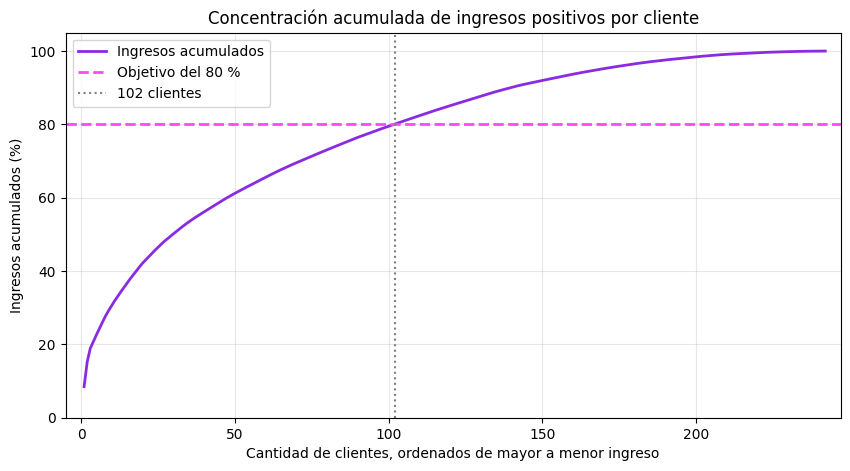

In [84]:
import matplotlib.pyplot as plt

# Graficamos la concentración acumulada de ingresos positivos por cliente.
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(clientes_positivos) + 1),
    clientes_positivos["PorcentajeAcumuladoPositivo"],
    color="#8A2BE2",
    linewidth=2,
    label="Ingresos acumulados"
)
plt.axhline(
    y=80, color="#FF47FF", linestyle="--", linewidth=2,
    label="Objetivo del 80 %"
)
plt.axvline(
    x=cantidad_clientes_80_positivos, color="#808080", linestyle=":",
    linewidth=1.5, label=f"{cantidad_clientes_80_positivos} clientes"
)
plt.title("Concentración acumulada de ingresos positivos por cliente")
plt.xlabel("Cantidad de clientes, ordenados de mayor a menor ingreso")
plt.ylabel("Ingresos acumulados (%)")
plt.xlim(-5, len(clientes_positivos) + 5)
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Conclusión de la pregunta 3**

Al considerar únicamente los clientes con ingresos estimados positivos, se necesitaron **102 de los 242 clientes (42,15 %)** para alcanzar el **80,07 %** de los ingresos positivos de la muestra. Esto indica que el 80 % de esos ingresos no se concentra en unos pocos clientes. El análisis excluye saldos netos negativos o iguales a cero y no contempla los 97 registros sin ID de cliente identificable.


## **6.** Síntesis final

En la muestra de 400 registros, 121 de 350 productos acumulan el 80,13 % de los ingresos estimados. A su vez, 206 de 340 productos con ingresos positivos representan el 60,59 % del catálogo positivo y acumulan el 20,13 % de esos ingresos. Entre los clientes con ingresos positivos, 102 de 242 concentran el 80,07 %. Los resultados están limitados por devoluciones, precios cero y 97 registros sin ID de cliente.